---
title: "Drugs: four questions about medication use"
subtitle: "From dispensing history to reviewable patient and spending opportunities"
author: "Tuva Health"
format:
  html:
    theme: cosmo
    embed-resources: true
    toc: true
    toc-depth: 2
    toc-title: "In this notebook"
    code-fold: true
    code-summary: "Show code"
    code-copy: true
    title-block-banner: "#0a0a0a"
    include-in-header:
      text: |
        <style>
        :root{--bs-primary:#216b91;} body{color:#182c38;font-size:17px;}
        h1,h2,h3{color:#0a0a0a;} .quarto-title-banner h1{color:white;}
        .cell-output-display{overflow-x:auto;} .figure-explanation{color:#506477;font-size:.92rem;}
        table{font-variant-numeric:tabular-nums;} a{color:#216b91;}
        </style>
execute:
  enabled: false
---

[Source on GitHub](https://github.com/tuva-health/drugs) · [Data mart documentation](https://thetuvaproject.com/data-marts/drugs)

A pharmacy claim tells us that a medication was dispensed. Linking dispensing
history to CodeRx and Tuva condition groups helps answer four questions:

1. **Brand vs. Generic:** Who currently uses a brand with a generic alternative,
   and what payer-paid savings do comparable claims support?
2. **Needs Refill:** Who may need a maintenance refill, and what share of each
   of seven chronic-condition populations does that represent?
3. **Open Drug Gaps:** Who has one of 68 conditions recorded in the past year
   but no related medication dispensing during that same year?
4. **Drug Episodes:** What are the start and end dates of a course of the same
   ingredient combination and dose form?

CodeRx Open supports the first three use cases. Enterprise adds broader drug
coverage and enables Drug Episodes. The single `use_coderx_enterprise` setting
selects the tier when the mart is built.

These results support review. A dispensing does not prove ingestion, and an
absent claim can reflect an incomplete feed, a cash purchase or a clinical
decision. The notebook keeps the evidence and its limitations beside each result.


## Start with the data you can observe

Change only the database name in the next SQL cell. All analytical queries
expect the final schema name `drugs` and include all data sources. The root
dbt project's schema policy must produce that name. Run the cells in
order. Snowflake SQL cells expose named results to the Python chart cells;
Python requires pandas, NumPy and Matplotlib.

This notebook reads an already-built mart. Its assessment date comes from
the mart, not the date you open this file. A fixed `drugs_as_of_date` supports
a reproducible comparison but does not recreate a historical warehouse.

Patient identity includes both `person_id` and `data_source`. Counts across
sources do not deduplicate the same real person across payers. A patient can
also appear under more than one condition or drug product.

The `.ipynb` format is standard; the SQL-result bindings use Snowflake notebook
metadata. Other platforms may need their own result binding to execute charts.

### Synthetic examples

The published Tuva synthetic pharmacy records have no days-supply values.
They can still provide dated medication evidence for the annual gap screen;
the mart does not invent supply for refills, current brand use or episodes.
Separate, deliberately constructed scenarios supply known fills, duration
and payer-paid prices so those calculations can be inspected. These are method
demonstrations, not findings about real patients.

The saved example uses **CodeRx Enterprise**, assessed as of **November 10,
2026**. All 13 analytical SQL queries were executed in Snowflake against the
isolated synthetic validation build; Python charts were generated locally
from those exact results. The database setup remains a placeholder. This
validates the example queries and charts, not execution on every notebook platform.

The `scenario_coverage` source deliberately includes a no-treatment example
for each of the 68 conditions. Other scenario sources exercise fill history,
unknown duration, source isolation and pricing. Their counts are constructed
to test the method and should not be interpreted as population prevalence.


In [ ]:
USE DATABASE YOUR_DATABASE;


In [1]:
import html
import textwrap
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib import dates as mdates
from IPython.display import display, HTML

def as_pandas(result):
    # Snowflake supplies Snowpark DataFrames; a local runner can supply pandas.
    if hasattr(result, 'to_pandas'):
        frame = result.to_pandas()
    elif hasattr(result, 'toPandas'):
        frame = result.toPandas()
    else:
        frame = result.copy()
    frame.columns = [str(c).lower() for c in frame.columns]
    for column in frame.columns:
        if any(isinstance(v, Decimal) for v in frame[column].dropna().head(10)):
            frame[column] = pd.to_numeric(frame[column])
    return frame

BLUE, SKY, YELLOW, INK, MUTED = '#216b91', '#66b1e2', '#ffcc08', '#0a0a0a', '#617481'
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 17, 'axes.titleweight': 'bold',
    'text.color': INK, 'axes.labelcolor': INK, 'axes.edgecolor': '#bdc9cf',
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'figure.dpi': 145, 'savefig.dpi': 170,
    'axes.spines.top': False, 'axes.spines.right': False,
})

def finish(fig, caption):
    fig.tight_layout()
    display(fig)
    display(HTML('<p class="figure-explanation">' + html.escape(caption) + '</p>'))
    plt.close(fig)

def no_rows(message):
    display(HTML('<p><strong>No rows to chart.</strong> ' + html.escape(message) + '</p>'))

def wrap(value, width=38):
    return textwrap.fill(str(value), width=width)

def episodes_enabled():
    status = as_pandas(terminology_result)
    return not status.empty and int(status.iloc[0]['drug_episodes_enabled_flag']) == 1

def enterprise_required(workflow):
    display(HTML('<p><strong>CodeRx Enterprise required.</strong> ' +
                 html.escape(workflow) + ' is not enabled for this Open build. ' +
                 'The empty episode table does not mean nobody received medication.</p>'))


In [2]:
SELECT assessment_date, terminology_tier, capability_status,
       brand_generic_enabled_flag, needs_refill_enabled_flag,
       drug_gaps_enabled_flag, drug_episodes_enabled_flag
FROM drugs.terminology_status;


assessment_date,terminology_tier,capability_status,brand_generic_enabled_flag,needs_refill_enabled_flag,drug_gaps_enabled_flag,drug_episodes_enabled_flag
2026-11-10,enterprise,enterprise_episodes_and_broader_terminology,1,1,1,1


The first three workflows run with either CodeRx tier. Episodes require the
Enterprise ingredient-combination and dose-form fields. Check the capability
flags before interpreting an empty episode table.

The evaluated catalogs contain 21,440 Open drug records and 66,471 Enterprise
drug records. These are observed snapshots, not fixed coverage guarantees or
counts of unique ingredients. A larger catalog can recognize more claims;
it does not make an incomplete source feed complete.


In [3]:
SELECT data_source, assessment_date,
       source_rx_file_date, source_rx_ingest_datetime,
       source_rx_freshness_date, source_rx_freshness_basis,
       source_latest_fill_date,
       DATEDIFF(day, source_rx_freshness_date, assessment_date) AS source_file_age_days,
       DATEDIFF(day, source_latest_fill_date, assessment_date) AS clinical_lag_days
FROM drugs.source_freshness
ORDER BY data_source;


data_source,assessment_date,source_rx_file_date,source_rx_ingest_datetime,source_rx_freshness_date,source_rx_freshness_basis,source_latest_fill_date,source_file_age_days,clinical_lag_days
medicare cclf,2026-11-10,2018-12-01,2025-08-26 08:01:29,2018-12-01,file_date,2018-12-22,2901,2880
scenario_clinical,2026-11-10,2026-11-10,2026-11-10 08:00:00,2026-11-10,file_date,2026-11-01,0,9
scenario_coverage,2026-11-10,2026-11-10,2026-11-10 08:00:00,2026-11-10,file_date,2026-11-01,0,9
scenario_economics,2026-11-10,2026-11-10,2026-11-10 08:00:00,2026-11-10,file_date,2026-11-01,0,9
scenario_economics_other,2026-11-10,2026-11-10,2026-11-10 08:00:00,2026-11-10,file_date,2026-10-20,0,21
scenario_other,2026-11-10,2026-11-10,2026-11-10 08:00:00,2026-11-10,file_date,2026-11-01,0,9


In [4]:
SELECT data_source, exposure_status, COUNT(*) AS medication_records
FROM drugs.medication
GROUP BY data_source, exposure_status
ORDER BY data_source, medication_records DESC, exposure_status;


data_source,exposure_status,medication_records
medicare cclf,missing_days_supply,291
scenario_clinical,usable,40
scenario_clinical,missing_days_supply,7
scenario_coverage,usable,1
scenario_economics,usable,7
scenario_economics_other,usable,1
scenario_other,usable,2


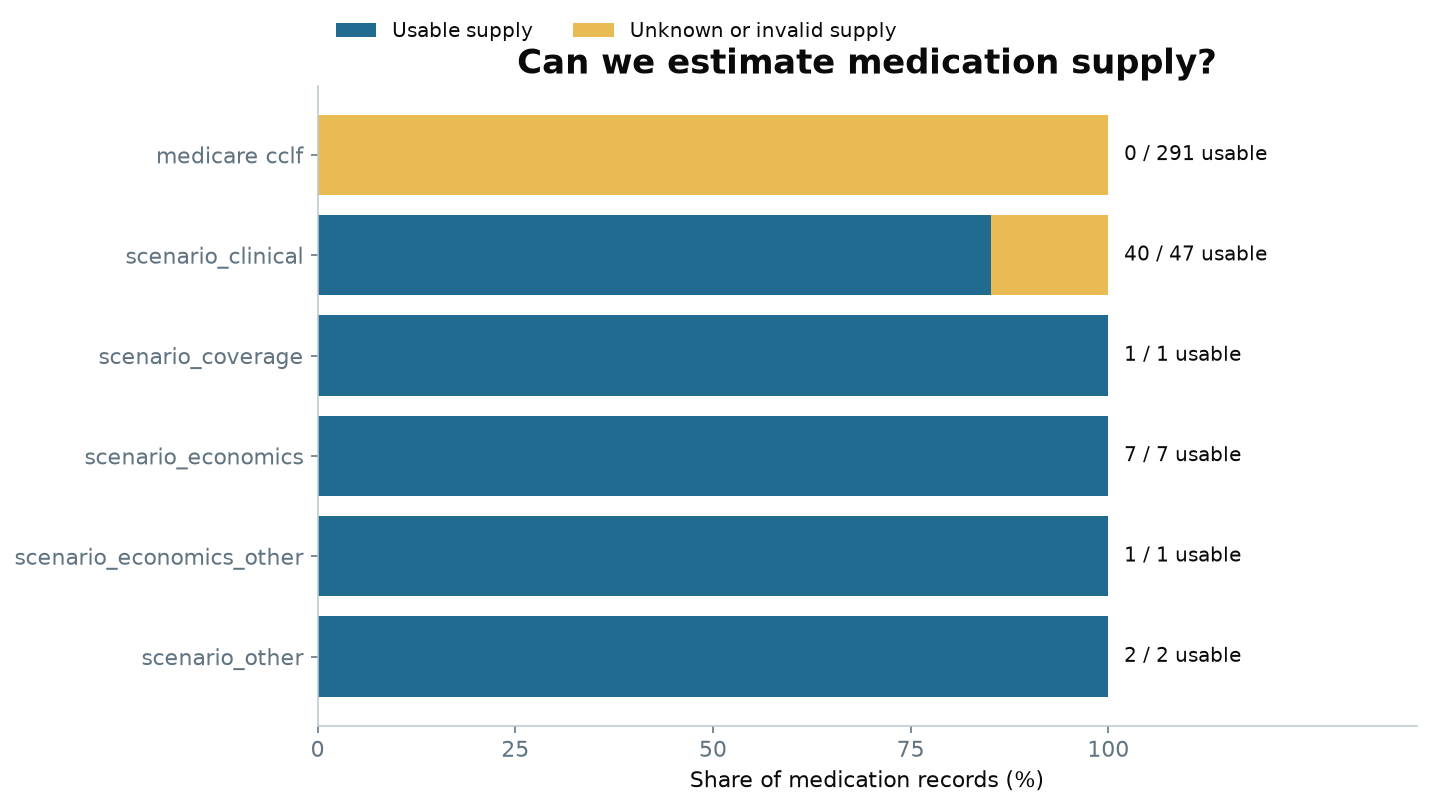

In [5]:
df = as_pandas(exposure_quality_result)
if df.empty:
    no_rows('No claims-derived medications were loaded.')
else:
    totals = df.groupby('data_source')['medication_records'].sum()
    usable = df.loc[df.exposure_status.eq('usable')].groupby('data_source')['medication_records'].sum()
    chart = pd.DataFrame({'total': totals, 'usable': usable}).fillna(0).sort_index()
    chart['unknown_or_invalid'] = chart.total - chart.usable
    fig, ax = plt.subplots(figsize=(10, max(3.2, len(chart) * .65 + 1.8)))
    y = np.arange(len(chart))
    usable_pct = 100 * chart.usable / chart.total
    ax.barh(y, usable_pct, color=BLUE, label='Usable supply')
    ax.barh(y, 100 - usable_pct, left=usable_pct, color='#e8bb54', label='Unknown or invalid supply')
    for i, row in enumerate(chart.itertuples()):
        ax.text(102, i, f'{int(row.usable):,} / {int(row.total):,} usable', va='center', fontsize=10)
    ax.set(yticks=y, yticklabels=[wrap(x, 30) for x in chart.index], xlim=(0, 139),
           xlabel='Share of medication records (%)', title='Can we estimate medication supply?')
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.04), ncol=2, frameon=False, fontsize=10)
    ax.invert_yaxis()
    finish(fig, 'Unknown days supply is a data limitation. It does not mean the patient stopped treatment or needs a refill.')


**What missing days supply changes.** An identifiable dispensing in the annual
window can rule out an annual drug gap even when duration is missing. Refill
dates, current brand opportunities and episodes need usable supply. The same
record can therefore be useful for one question and uncertain for another.


File date describes the delivered source file; ingestion time describes when
it was loaded. Reloading an old file does not make its clinical information
current. Latest dispensing date is a separate observation. None certifies
complete claims capture.

Patient worklists retain their own condition and medication evidence dates.
A source can be current while one patient's latest evidence is old. Unmapped
or undated medication can leave an annual gap uncertain. Missing days supply
alone does not invalidate a dated, mapped dispensing for that screen.


## 1. Brand vs. Generic: distinguish observed spending from potential savings

Start with historical payer-paid spending, then examine current switching
opportunities. A rise in observed brand spending and an estimated future
saving are different quantities. The first is a claims total; the second
assumes continued treatment after a hypothetical switch.

The next query groups claims by dispensing month over the assessment year's
365-day window. Unknown brand status and missing paid amounts stay visible.
Boundary months may be partial, and source freshness affects recent totals.


In [6]:
SELECT DATE_TRUNC('month', m.dispensing_date) AS dispensing_month,
       CASE WHEN m.brand_flag = 1 THEN 'Brand'
            WHEN m.brand_flag = 0 THEN 'Generic'
            ELSE 'Unknown brand status' END AS product_type,
       COUNT(*) AS fill_count,
       COUNT(m.paid_amount) AS fills_with_paid_amount,
       ROUND(SUM(m.paid_amount), 2) AS payer_paid_amount
FROM drugs.medication m
CROSS JOIN drugs.terminology_status s
WHERE m.dispensing_date BETWEEN DATEADD(day, -364, s.assessment_date)
                            AND s.assessment_date
GROUP BY DATE_TRUNC('month', m.dispensing_date),
         CASE WHEN m.brand_flag = 1 THEN 'Brand'
              WHEN m.brand_flag = 0 THEN 'Generic'
              ELSE 'Unknown brand status' END
ORDER BY dispensing_month, product_type;


dispensing_month,product_type,fill_count,fills_with_paid_amount,payer_paid_amount
2026-01-01,Generic,2,2,30.00
2026-03-01,Generic,1,1,15.00
2026-05-01,Generic,1,1,15.00
2026-08-01,Generic,1,1,15.00
2026-09-01,Generic,17,17,246.00
2026-10-01,Brand,4,4,690.00
2026-10-01,Generic,18,18,264.00
2026-11-01,Generic,14,14,201.00


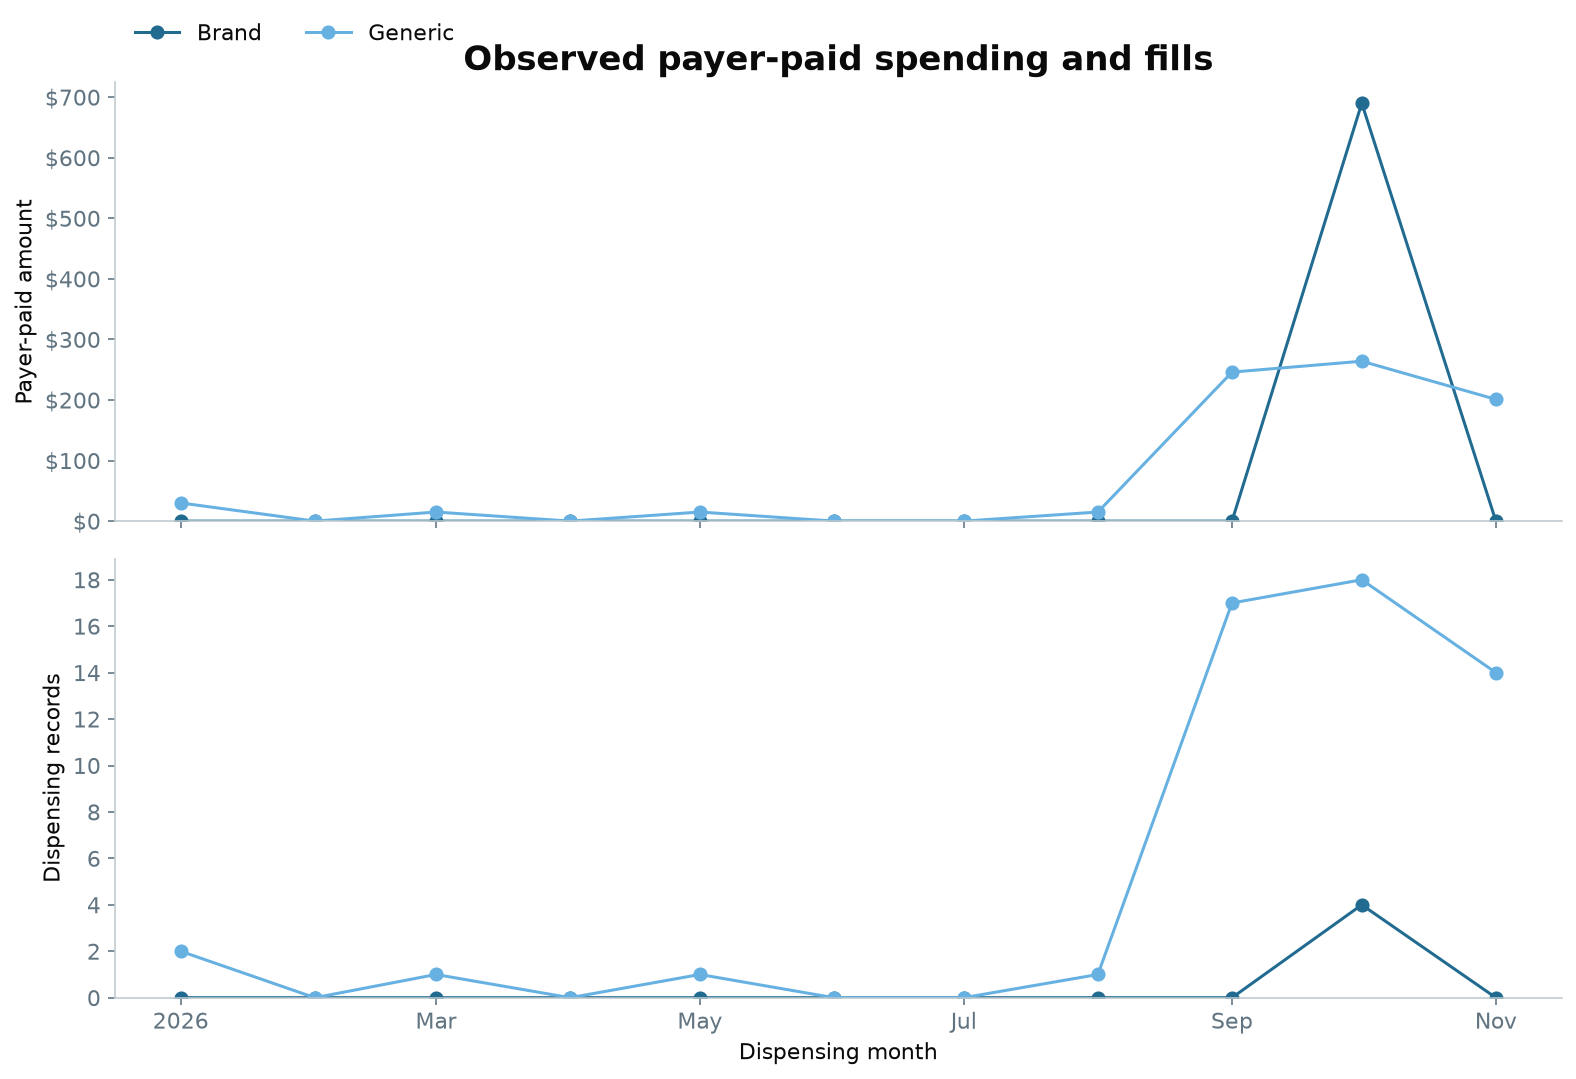

In [7]:
df = as_pandas(brand_history_result)
if df.empty:
    no_rows('No dated dispensing records fall within the assessment year.')
else:
    df['dispensing_month'] = pd.to_datetime(df.dispensing_month)
    df['payer_paid_amount'] = pd.to_numeric(df.payer_paid_amount, errors='coerce')
    colors = {'Brand': BLUE, 'Generic': SKY, 'Unknown brand status': '#b7a04b'}
    fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
    months = pd.date_range(df.dispensing_month.min(), df.dispensing_month.max(), freq='MS')
    for product_type, part in df.groupby('product_type'):
        part = part.set_index('dispensing_month')[['payer_paid_amount', 'fill_count']].reindex(months, fill_value=0)
        part = part.rename_axis('dispensing_month').reset_index()
        color = colors.get(product_type, MUTED)
        axes[0].plot(part.dispensing_month, part.payer_paid_amount, marker='o', label=product_type, color=color)
        axes[1].plot(part.dispensing_month, part.fill_count, marker='o', label=product_type, color=color)
    axes[0].set(title='Observed payer-paid spending and fills', ylabel='Payer-paid amount')
    axes[0].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'${value:,.0f}'))
    axes[0].legend(frameon=False, ncol=3, loc='upper left', bbox_to_anchor=(0, 1.18))
    axes[1].set(ylabel='Dispensing records', xlabel='Dispensing month')
    axes[1].yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    axes[1].set_ylim(bottom=0)
    if df.payer_paid_amount.dropna().ge(0).all():
        axes[0].set_ylim(bottom=0)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=8)
    axes[1].xaxis.set_major_locator(locator)
    axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    finish(fig, 'These are observed claims totals across all sources, not realized switching savings. Missing paid amounts are omitted from the spending total but included in fill counts. Months without observed claims are shown as zero. Partial months and reporting lag can affect the trend.')


### Current switching opportunities

The current list starts with branded supply estimated to cover the assessment
date. A generic alternative must share the same CodeRx clinical drug—ingredient,
strength and form—and be active and prescribable. Each source/patient/clinical
drug contributes one candidate. Clinical-product matching is not a therapeutic-
equivalence or formulary decision.

Pricing uses only payer-paid amounts. The median generic paid amount per unit
must come from comparable claims in the same source, payer, plan and clinical
product, with similar quantity per supply day. Defaults require three claims
from two people over 90 days. Unpriced candidates remain visible.

Package-level availability and generic price benchmarks require canonical 11-digit NDCs. Core's RxNorm fallback can support product, class and episode mapping, but does not reconstruct package-level marketing or pricing evidence.

The detail table also retains current brands with no catalog generic. The
summary and patient query below select only `generic_available_flag = 1`.
Enterprise includes explicitly labeled NDA authorized generics as candidates
and benchmark claims. Their `alternative_basis` in `generic_alternative` is
`active_authorized_generic_same_clinical_drug`; active/prescribable, date and
clinical-product checks still apply.


In [8]:
SELECT brand_drug, clinical_drug_id, generic_alternative,
       SUM(patients_who_could_switch) AS patients_who_could_switch,
       SUM(patients_with_savings_estimate) AS patients_with_savings_estimate,
       SUM(patients_without_savings_estimate) AS patients_without_savings_estimate,
       ROUND(SUM(annual_savings_for_priced_patients), 2)
           AS annual_savings_for_priced_patients,
       CASE WHEN SUM(patients_without_savings_estimate) = 0
            THEN ROUND(SUM(annual_savings_for_priced_patients), 2)
       END AS annual_savings_if_all_switched
FROM drugs.brand_generic_summary
GROUP BY brand_drug, clinical_drug_id, generic_alternative
ORDER BY annual_savings_for_priced_patients DESC NULLS LAST,
         brand_drug, clinical_drug_id;


brand_drug,clinical_drug_id,generic_alternative,patients_who_could_switch,patients_with_savings_estimate,patients_without_savings_estimate,annual_savings_for_priced_patients,annual_savings_if_all_switched
atorvastatin 20 MG Oral Tablet [Lipitor],617310,atorvastatin 20 MG Oral Tablet,3,2,1,"2,336.00",—


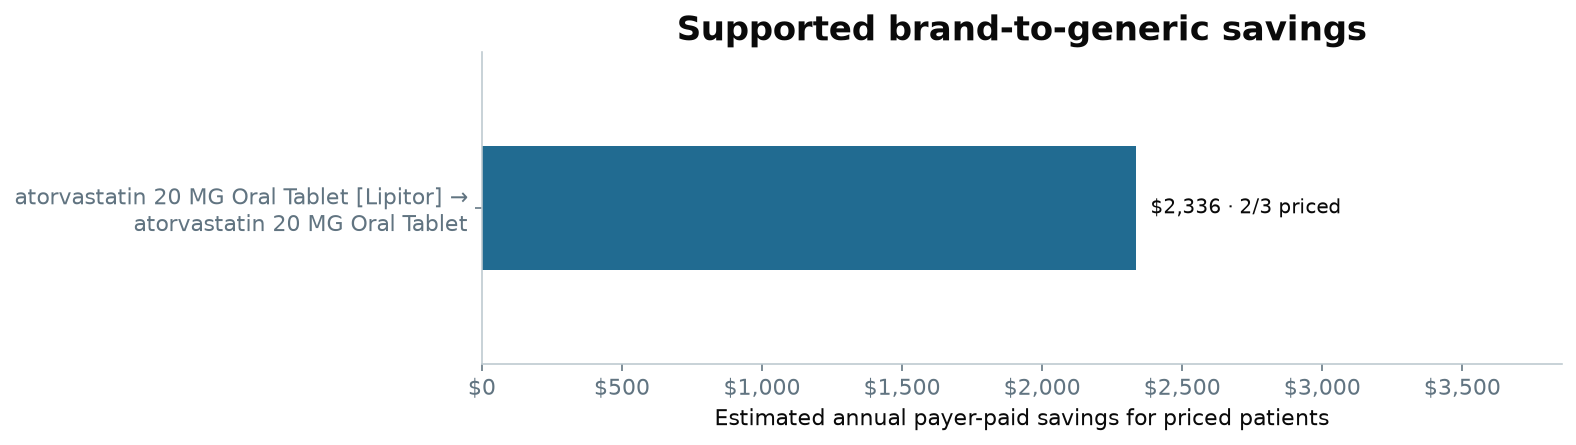

In [9]:
df = as_pandas(brand_generic_result)
if df.empty:
    no_rows('No current brand users with a catalog generic alternative met the opportunity definition.')
else:
    chart = df.sort_values('annual_savings_for_priced_patients', ascending=False, na_position='last').head(10).iloc[::-1].copy()
    values = pd.to_numeric(chart.annual_savings_for_priced_patients, errors='coerce')
    fig, ax = plt.subplots(figsize=(11, max(3.2, len(chart) * 1.05 + 1.5)))
    y = np.arange(len(chart))
    ax.barh(y, values.fillna(0), color=BLUE, height=.52)
    for i, row in enumerate(chart.itertuples()):
        priced, candidates = int(row.patients_with_savings_estimate), int(row.patients_who_could_switch)
        if pd.isna(row.annual_savings_for_priced_patients):
            label, x = f'No supported estimate · {candidates} candidates', 0
        else:
            label, x = f'${row.annual_savings_for_priced_patients:,.0f} · {priced}/{candidates} priced', row.annual_savings_for_priced_patients
        ax.annotate(label, (x, i), xytext=(7, 0), textcoords='offset points', va='center', fontsize=10)
    labels = [wrap(f'{r.brand_drug} → {r.generic_alternative}', 46) for r in chart.itertuples()]
    max_value = values.max() if values.notna().any() else 0
    ax.set(yticks=y, yticklabels=labels, xlabel='Estimated annual payer-paid savings for priced patients',
           title='Supported brand-to-generic savings')
    ax.set_xlim(0, max(1, max_value) * 1.65)
    ax.set_ylim(-.65, len(chart) - .35)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v:,.0f}'))
    finish(fig, 'The chart shows the priced subtotal for up to ten clinical products. It is not an estimate for unpriced patients. Use annual_savings_if_all_switched only when every candidate has a supported price.')


**Read the two savings columns differently.** The priced subtotal covers only
patients with a supported benchmark. The all-patients estimate is null when
any candidate is unpriced. Neither estimate includes rebates or switching
costs; annualization assumes continued treatment at current utilization and prices.

**Constructed result.** Three current Lipitor 20 mg users have a catalog
generic alternative. Two have supported prices, totaling **$2,336** in
estimated annual payer-paid savings. The third is unpriced, so the estimate
for switching all three is null.


### Keep the benchmark evidence with the estimated savings

The patient/product table below shows why an opportunity is priced or
unpriced, the number of comparable generic claims and people, and the source
freshness. Aggregate this parent table before joining the one-to-many list of
generic NDCs; otherwise, alternative packages would multiply patient counts
and dollars.


In [10]:
SELECT data_source, person_id, drug_name AS brand_drug,
       clinical_drug_name, generic_alternative_name,
       generic_ndc_count, pricing_status,
       benchmark_claim_count, benchmark_person_count,
       benchmark_first_fill_date, benchmark_last_fill_date,
       estimated_savings_per_30_days, estimated_annual_savings,
       brand_file_date, benchmark_file_date, source_rx_freshness_date,
       outreach_readiness_status
FROM drugs.brand_generic_opportunity
WHERE generic_available_flag = 1
ORDER BY estimated_annual_savings DESC NULLS LAST, data_source, person_id, clinical_drug_id
LIMIT 20;


data_source,person_id,brand_drug,clinical_drug_name,generic_alternative_name,generic_ndc_count,pricing_status,benchmark_claim_count,benchmark_person_count,benchmark_first_fill_date,benchmark_last_fill_date,estimated_savings_per_30_days,estimated_annual_savings,brand_file_date,benchmark_file_date,source_rx_freshness_date,outreach_readiness_status
scenario_economics,sc_brand_a,atorvastatin 20 MG Oral Tablet [Lipitor],atorvastatin 20 MG Oral Tablet,atorvastatin 20 MG Oral Tablet,396,priced_for_review,4.00,3.00,2026-09-01,2026-11-01,111.00,"1,350.50",2026-11-10,2026-11-10,2026-11-10,current_record_review
scenario_economics,sc_brand_b,atorvastatin 20 MG Oral Tablet [Lipitor],atorvastatin 20 MG Oral Tablet,atorvastatin 20 MG Oral Tablet,396,priced_for_review,4.00,3.00,2026-09-01,2026-11-01,81.00,985.50,2026-11-10,2026-11-10,2026-11-10,current_record_review
scenario_economics_other,sc_brand_a,atorvastatin 20 MG Oral Tablet [Lipitor],atorvastatin 20 MG Oral Tablet,atorvastatin 20 MG Oral Tablet,396,insufficient_paid_benchmark,—,—,—,—,—,—,2026-11-10,—,2026-11-10,current_record_review


## 2. Needs Refill: put the worklist in population context

Refill reporting covers Type 2 Diabetes, Hypertension, Coronary Artery Disease,
COPD, Asthma, Heart Failure, and Atrial Fibrillation and Flutter. It requires
at least two distinct maintenance dispensing dates for the same clinical product
in the past year and known,
usable supply. The default due-date window is seven days ahead through 30 days
overdue. Due date is the day after estimated supply ends.

The denominator is the living condition population in sources with an observed
pharmacy feed, including patients with no previous fills or uncertain supply.
Sum the numerator and denominator before calculating a percentage across sources;
do not average source-level percentages. A null percentage means no denominator.


In [11]:
SELECT condition_code, condition_name,
       SUM(patients_needing_refill) AS patients_needing_refill,
       SUM(refill_denominator_patients) AS number_with_condition,
       ROUND(100.0 * SUM(patients_needing_refill)
             / NULLIF(SUM(refill_denominator_patients), 0), 2)
           AS percent_needing_refill,
       SUM(refill_unassessable_patients) AS refill_unassessable_patients
FROM drugs.condition_summary
WHERE refill_condition_eligible_flag = 1
GROUP BY condition_code, condition_name
ORDER BY patients_needing_refill DESC, condition_name;


condition_code,condition_name,patients_needing_refill,number_with_condition,percent_needing_refill,refill_unassessable_patients
asthma,Asthma,2,6,33.33,1
afib,Atrial Fibrillation and Flutter,1,5,20.00,1
copd,Chronic Obstructive Pulmonary Disease,1,5,20.00,1
cad,Coronary Artery Disease,1,5,20.00,1
chf,Heart Failure,1,6,16.67,1
htn,Hypertension,1,6,16.67,1
t2d,Type 2 Diabetes Mellitus,1,6,16.67,2


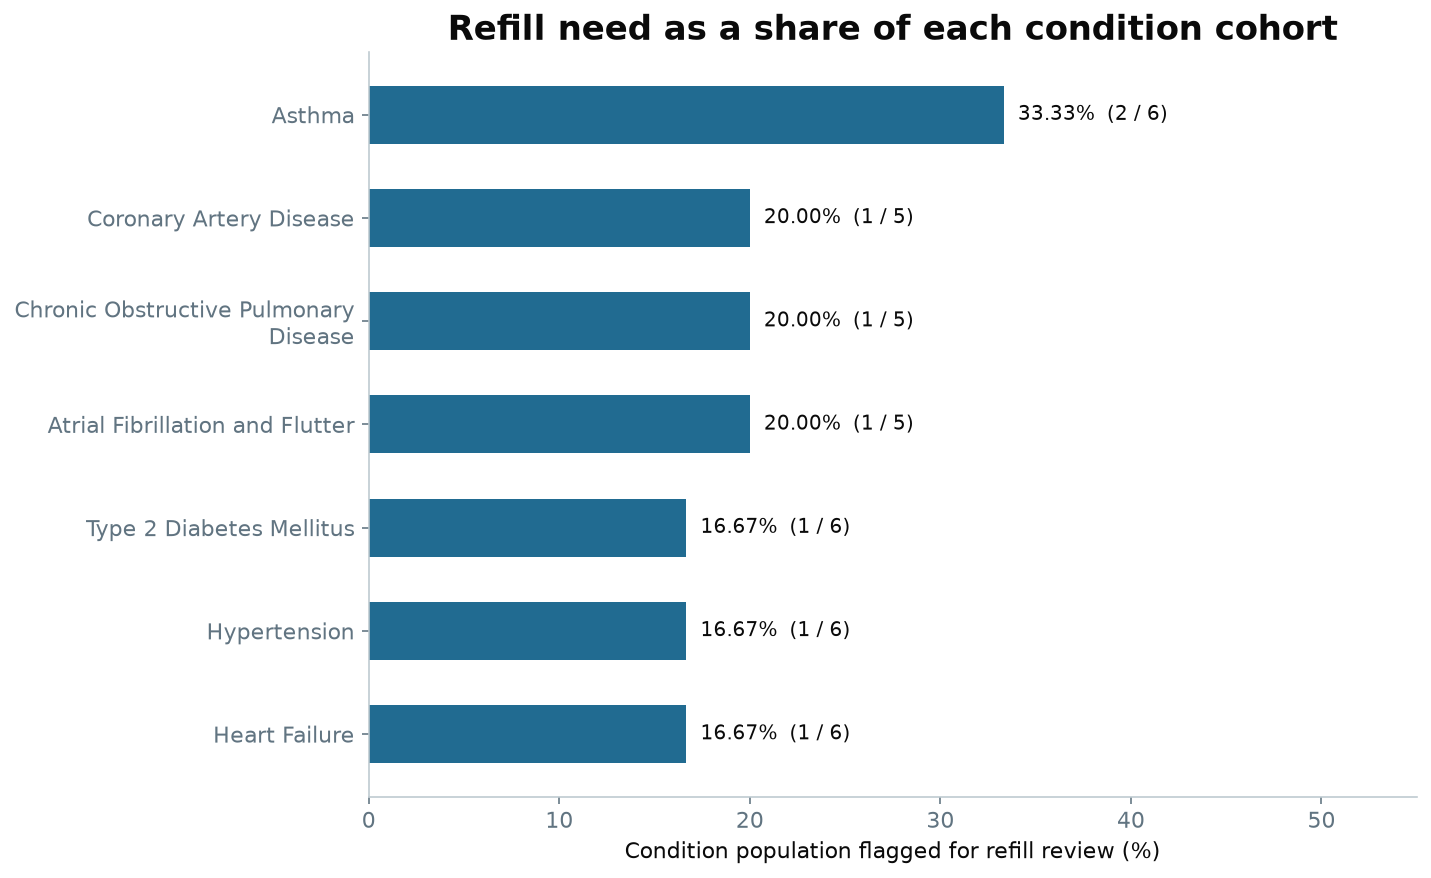

In [12]:
df = as_pandas(refill_counts_result).sort_values(['percent_needing_refill', 'condition_name'], na_position='first')
if df.empty:
    no_rows('No qualifying condition population is present.')
else:
    fig, ax = plt.subplots(figsize=(10, max(4, len(df) * .67 + 1.5)))
    values = pd.to_numeric(df.percent_needing_refill, errors='coerce')
    y = np.arange(len(df))
    ax.barh(y, values.fillna(0), color=BLUE, height=.56)
    for i, row in enumerate(df.itertuples()):
        if pd.isna(row.percent_needing_refill):
            label, x = 'No eligible denominator', 0
        else:
            label, x = f'{row.percent_needing_refill:.2f}%  ({int(row.patients_needing_refill):,} / {int(row.number_with_condition):,})', row.percent_needing_refill
        ax.annotate(label, (x, i), xytext=(7, 0), textcoords='offset points', va='center', fontsize=10)
    max_pct = values.max() if values.notna().any() else 0
    ax.set(yticks=y, yticklabels=[wrap(x, 36) for x in df.condition_name],
           xlabel='Condition population flagged for refill review (%)',
           title='Refill need as a share of each condition cohort')
    ax.set_xlim(0, max(10, max_pct * 1.65))
    finish(fig, 'Labels show the flagged count divided by the condition denominator. Unknown exposure remains in the denominator, so low percentages can reflect incomplete data rather than successful medication management.')


**A low rate is not automatically good performance.** Unknown exposure stays
in the denominator. Review the unassessable count and source freshness before
comparing populations. The worklist selects one candidate per condition;
current maintenance supply can suppress an overdue component of a multidrug
regimen. It does not identify every individual drug refill.

Repeated fills from a curated mixed ATC class can remain candidates with
`refill_class_confidence = 'possible'`. Confirm the indication and whether
use is scheduled or as needed. This differs from annual gaps, where a
possible-only class match remains uncertain rather than closing the gap.

**Constructed result.** The asthma cohort has two potential refill candidates
among six patients, or **33.33%**. The denominator includes the deliberately
untreated coverage example and the patient with uncertain supply.


In [13]:
SELECT data_source, condition_name, patients_needing_refill,
       refill_denominator_patients, percent_needing_refill,
       refill_unassessable_patients
FROM drugs.condition_summary
WHERE refill_condition_eligible_flag = 1
ORDER BY data_source, condition_name;


data_source,condition_name,patients_needing_refill,refill_denominator_patients,percent_needing_refill,refill_unassessable_patients
scenario_clinical,Asthma,2,5,40.00,1
scenario_clinical,Atrial Fibrillation and Flutter,1,4,25.00,1
scenario_clinical,Chronic Obstructive Pulmonary Disease,1,4,25.00,1
scenario_clinical,Coronary Artery Disease,1,4,25.00,1
scenario_clinical,Heart Failure,1,5,20.00,1
scenario_clinical,Hypertension,1,5,20.00,1
scenario_clinical,Type 2 Diabetes Mellitus,1,4,25.00,1
scenario_coverage,Asthma,0,1,0.00,0
scenario_coverage,Atrial Fibrillation and Flutter,0,1,0.00,0
scenario_coverage,Chronic Obstructive Pulmonary Disease,0,1,0.00,0


### Review the due date and the fill that produced it

The next list starts with the condition with the most refill candidates.
`drug_associated_with_refill_due_date` is the maintenance fill whose supply
end determines the due date, which is not necessarily the latest dispensing
date. Negative days overdue means due soon; zero means due on the assessment
date. Confirm that the treatment is still intended and scheduled before
acting, especially when the source is lagged.

The treatment evidence file date and ingestion timestamp belong to the same
selected fill. Missing timestamps stay missing rather than being replaced
with dates from another related medication.


In [14]:
WITH selected_condition AS (
    SELECT condition_code
    FROM drugs.condition_summary
    GROUP BY condition_code
    HAVING SUM(patients_needing_refill) > 0
    ORDER BY SUM(patients_needing_refill) DESC, condition_code
    LIMIT 1
)
SELECT r.data_source, r.person_id, r.condition_name,
       r.latest_maintenance_medication_id,
       r.latest_maintenance_drug_name AS drug_associated_with_refill_due_date,
       r.maintenance_fill_dates, r.estimated_refill_due_date,
       r.days_overdue, r.refill_status, r.refill_class_confidence,
       r.treatment_evidence_file_date, r.treatment_evidence_ingest_datetime,
       r.source_rx_freshness_date, r.outreach_readiness_status
FROM drugs.needs_refill r
JOIN selected_condition s ON r.condition_code = s.condition_code
ORDER BY CASE WHEN r.outreach_readiness_status = 'current_record_review' THEN 0 ELSE 1 END,
         r.days_overdue DESC, r.data_source, r.person_id
LIMIT 20;


data_source,person_id,condition_name,latest_maintenance_medication_id,drug_associated_with_refill_due_date,maintenance_fill_dates,estimated_refill_due_date,days_overdue,refill_status,refill_class_confidence,treatment_evidence_file_date,treatment_evidence_ingest_datetime,source_rx_freshness_date,outreach_readiness_status
scenario_clinical,sc_asthma_overdue,Asthma,sc_asthma_overdue_asthma_20261001-1-scenario_clinical,montelukast 10 MG Oral Tablet,2,2026-10-31,10,overdue,qualifying,2026-11-10,2026-11-10 08:00:00,2026-11-10,current_record_review
scenario_clinical,sc_asthma_rescue,Asthma,sc_asthma_rescue_asthma_20261001-1-scenario_clinical,montelukast 10 MG Oral Tablet,2,2026-10-31,10,overdue,qualifying,2026-11-10,2026-11-10 08:00:00,2026-11-10,current_record_review


## 3. Open Drug Gaps: find no related dispensing in the past year

The annual gap screen covers 68 Tuva-grouper conditions. It looks for condition
evidence dated within the 365 days ending on the assessment date, then checks
for any related claims dispensing in that same window. Completed courses count.
Neither days supply nor active medication supply today is required.

Each condition uses one OR across its accepted CodeRx ATC classes. A patient
does not need every class. Classes with unrelated products provide possible
treatment evidence; a possible-only match is uncertain rather than a definite
treated or untreated result. Unmapped or undated medication and missing pharmacy
feeds also prevent a definite gap.

The condition summary separates potential gaps from uncertain assessments.
The chart shows up to 15 conditions; the query retains the complete result.


In [15]:
SELECT condition_code, condition_name,
       SUM(patients_with_open_gaps) AS patients_with_open_gaps,
       SUM(gap_unassessable_patients) AS gap_unassessable_patients,
       SUM(current_record_gap_patients) AS current_record_gap_patients
FROM drugs.condition_summary
GROUP BY condition_code, condition_name
ORDER BY patients_with_open_gaps DESC, condition_name;


condition_code,condition_name,patients_with_open_gaps,gap_unassessable_patients,current_record_gap_patients
asthma,Asthma,2,0,2
afib,Atrial Fibrillation and Flutter,2,3,2
copd,Chronic Obstructive Pulmonary Disease,2,0,2
cad,Coronary Artery Disease,2,3,2
chf,Heart Failure,2,3,2
htn,Hypertension,2,0,2
t2d,Type 2 Diabetes Mellitus,2,1,2
abdominal_aortic_aneurysm,Abdominal Aortic Aneurysm,1,0,1
acute_myocardial_infarction,Acute Myocardial Infarction,1,0,1
alcohol_use_disorder,Alcohol Use Disorder,1,0,1


Displaying 30 of 68 result rows.


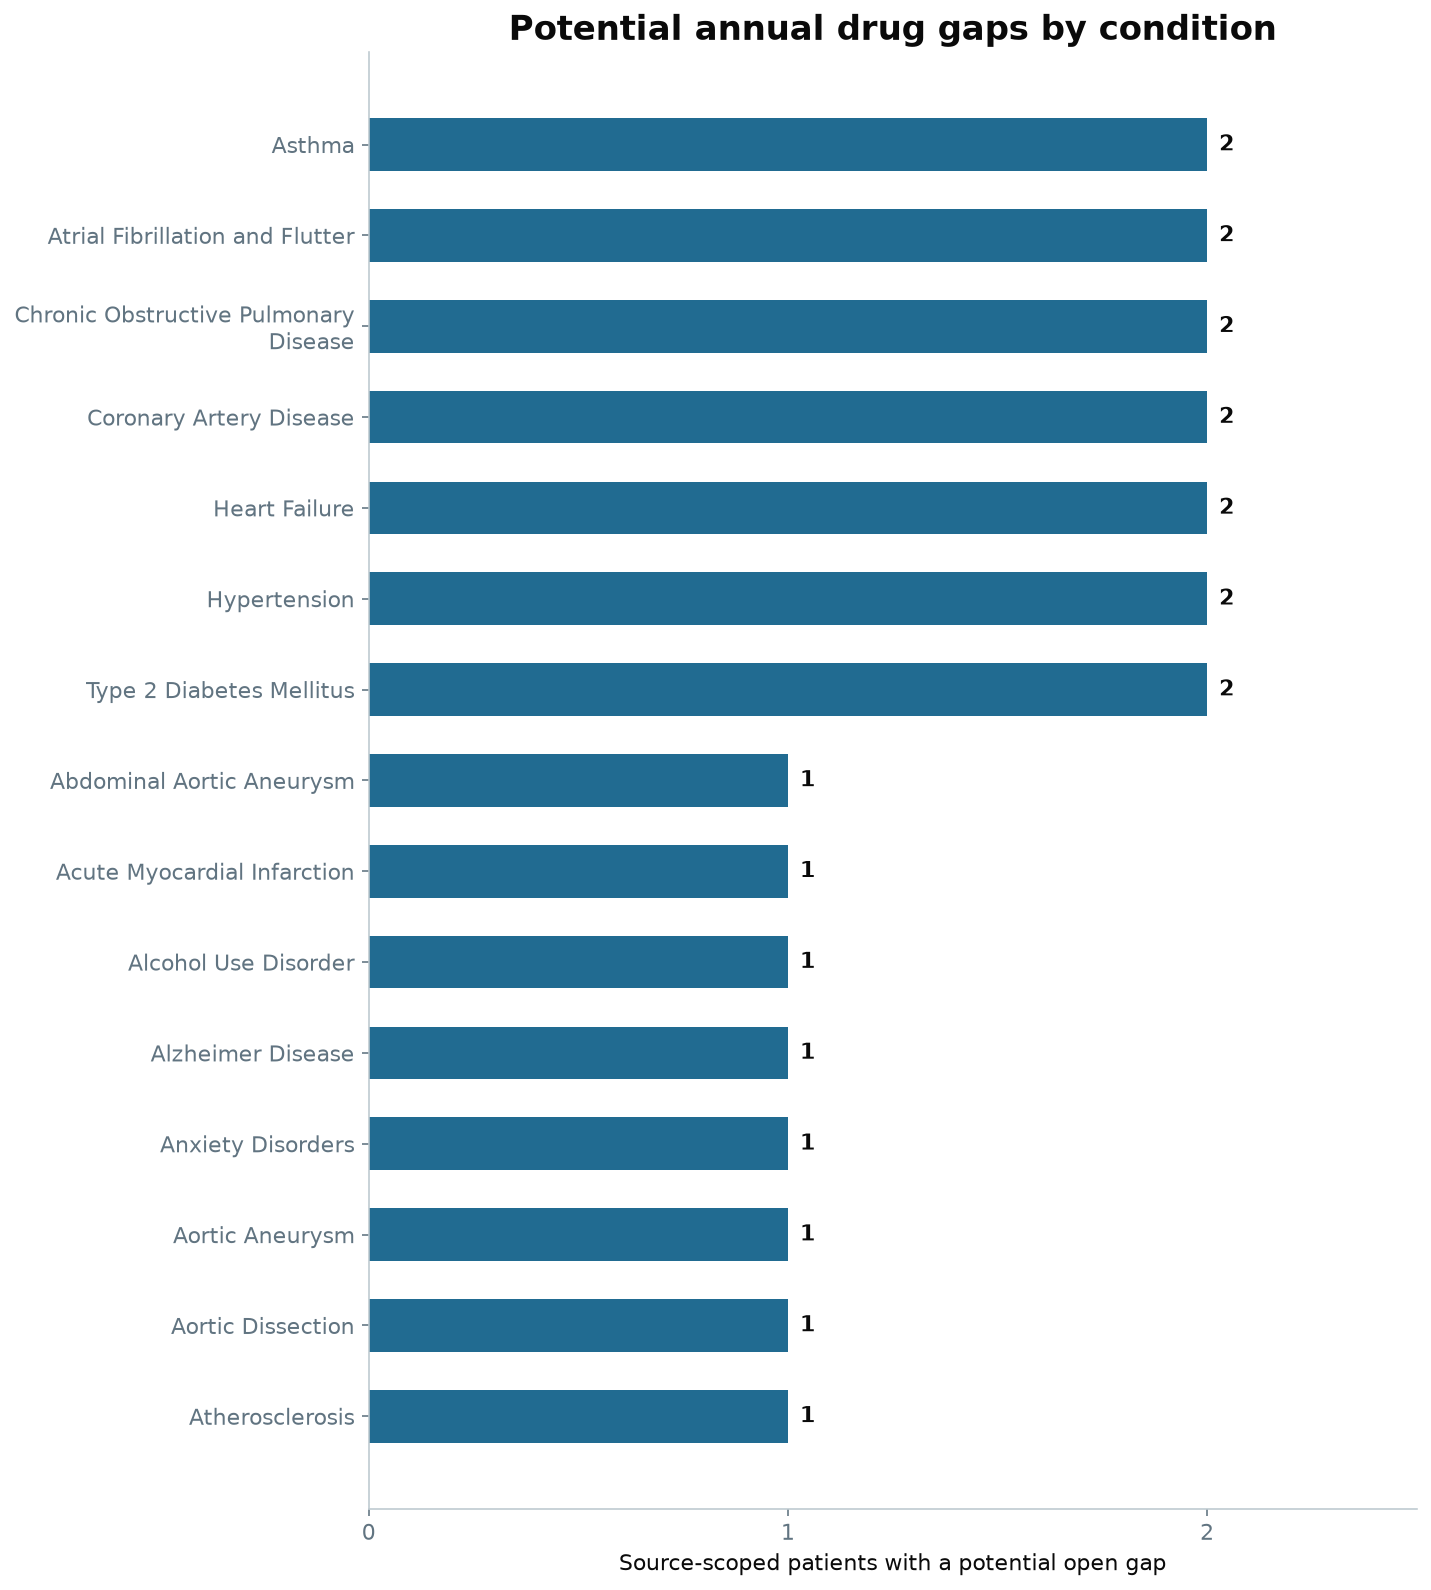

In [16]:
df = as_pandas(gap_counts_result).sort_values(['patients_with_open_gaps', 'condition_name'], ascending=[False, True]).head(15).iloc[::-1]
if df.empty:
    no_rows('No qualifying condition evidence is present in the configured lookback.')
else:
    fig, ax = plt.subplots(figsize=(10, max(4, len(df) * .64 + 1.5)))
    y = np.arange(len(df))
    ax.barh(y, df.patients_with_open_gaps, color=BLUE, height=.58)
    for i, row in enumerate(df.itertuples()):
        ax.annotate(f'{int(row.patients_with_open_gaps):,}', (row.patients_with_open_gaps, i),
                    xytext=(6, 0), textcoords='offset points', va='center', fontweight='bold')
    ax.set(yticks=y, yticklabels=[wrap(x, 36) for x in df.condition_name],
           xlabel='Source-scoped patients with a potential open gap',
           title='Potential annual drug gaps by condition')
    ax.set_xlim(0, max(1, df.patients_with_open_gaps.max()) * 1.25)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    finish(fig, 'Up to 15 conditions are shown. Unknown assessments are excluded from gap counts and reported separately in the table. A person can have several conditions, so condition counts should not be added to estimate unique patients.')


**Interpret absence in context.** A related dispensing means that a claim was
observed, not that treatment was adequate or complete. Conversely, no claim
can reflect non-drug management, OTC products, samples or cash fills. A person
with an overdue refill can still have related dispensing in the past year and
therefore have no annual drug gap.


### From a condition count to the underlying patients

The next query chooses the condition with the largest gap count and returns
up to 20 review candidates across all sources. It retains the diagnosis date,
treatment history and freshness. Current enrollment is a review context;
unconfirmed enrollment does not disappear from the worklist. Known deceased
patients are excluded.


In [17]:
WITH selected_condition AS (
    SELECT condition_code
    FROM drugs.condition_summary
    GROUP BY condition_code
    HAVING SUM(patients_with_open_gaps) > 0
    ORDER BY SUM(patients_with_open_gaps) DESC, condition_code
    LIMIT 1
)
SELECT g.data_source, g.person_id, g.condition_code, g.condition_name,
       g.last_condition_date, g.gap_assessment_basis,
       g.qualifying_condition_fill_count, g.possible_condition_fill_count,
       g.condition_freshness_date, g.patient_rx_freshness_date,
       g.source_rx_freshness_date, g.source_clinical_lag_days,
       g.outreach_readiness_status
FROM drugs.open_drug_gap g
JOIN selected_condition s ON g.condition_code = s.condition_code
ORDER BY CASE WHEN g.outreach_readiness_status = 'current_record_review' THEN 0 ELSE 1 END,
         g.data_source, g.person_id
LIMIT 20;


data_source,person_id,condition_code,condition_name,last_condition_date,gap_assessment_basis,qualifying_condition_fill_count,possible_condition_fill_count,condition_freshness_date,patient_rx_freshness_date,source_rx_freshness_date,source_clinical_lag_days,outreach_readiness_status
scenario_clinical,sc_afib_never,afib,Atrial Fibrillation and Flutter,2026-10-01,365_day_class_dispensing,0,0,2026-11-10,None,2026-11-10,9,current_record_review
scenario_coverage,sc_coverage_afib,afib,Atrial Fibrillation and Flutter,2026-11-01,365_day_class_dispensing,0,0,2026-11-10,None,2026-11-10,9,current_record_review


## 4. Drug Episodes: follow a combination and dose form over time

This use case requires CodeRx Enterprise. An episode follows the complete
ingredient combination and dose form, independent of strength or brand.
Combination products remain one combination; a different combination or form
has its own track. `drug_code` is CodeRx's ingredient identifier, usually an
RxNorm IN or MIN concept. `drug_code_system` identifies rare vendor group IDs
that are not a single RxCUI.

Supply starts on dispensing date and ends on dispensing date + days supply − 1.
Overlapping supply is unioned, without default stockpiling. Up to 30 uncovered
days can connect fills; 31 starts another episode. That tolerance does not fill
the hole or extend the last supply date. Refill authorizations create no supply.

The query samples eight episodes per source so the timeline stays readable.
The mapping table below reports records that lack enough ingredient or form
information to construct an episode.


In [18]:
WITH ranked AS (
    SELECT episode_id, data_source, person_id, drug_code, drug_name,
           drug_code_system, ingredient_type, dose_form_id, dose_form_name,
           start_date, end_date, fill_count, covered_days, uncovered_days,
           active_supply_flag, assessment_date,
           ROW_NUMBER() OVER (
               PARTITION BY data_source
               ORDER BY uncovered_days DESC, restart_flag DESC,
                        person_id, drug_name, start_date, episode_id
           ) AS sample_rank
    FROM drugs.drug_episode
)
SELECT episode_id, data_source, person_id, drug_code, drug_name,
           drug_code_system, ingredient_type, dose_form_id, dose_form_name,
       start_date, end_date, fill_count, covered_days, uncovered_days,
       active_supply_flag, assessment_date
FROM ranked
WHERE sample_rank <= 8
ORDER BY data_source, person_id, drug_name, start_date;


episode_id,data_source,person_id,drug_code,drug_name,drug_code_system,ingredient_type,dose_form_id,dose_form_name,start_date,end_date,fill_count,covered_days,uncovered_days,active_supply_flag,assessment_date
c55f278d82f5597427c355fd8846b765,scenario_clinical,sc_afib_current,1037042,dabigatran etexilate,RxNorm,IN,316965,oral capsule,2026-09-20,2026-11-18,2,60,0,1,2026-11-10
e3a337c0412cbd459008843539e765a1,scenario_clinical,sc_afib_overdue,1037042,dabigatran etexilate,RxNorm,IN,316965,oral capsule,2026-09-01,2026-10-30,2,60,0,0,2026-11-10
a6b0332a215853a6f7dc09392b15569a,scenario_clinical,sc_asthma_current,88249,montelukast,RxNorm,IN,317541,oral tablet,2026-09-20,2026-11-18,2,60,0,1,2026-11-10
0cb629bcbbca7d0eece16f804165bb76,scenario_clinical,sc_asthma_overdue,88249,montelukast,RxNorm,IN,317541,oral tablet,2026-09-01,2026-10-30,2,60,0,0,2026-11-10
899ccece8b8ca73ce91b0975b153403b,scenario_clinical,sc_asthma_rescue,435,albuterol,RxNorm,IN,721654,metered dose inhaler,2026-11-01,2026-11-30,1,30,0,1,2026-11-10
ea12a28c92f39cd96998edccb337808f,scenario_clinical,sc_asthma_rescue,88249,montelukast,RxNorm,IN,317541,oral tablet,2026-09-01,2026-10-30,2,60,0,0,2026-11-10
b4c67d3f5722ba0a9669b84b2a3e9d6c,scenario_clinical,sc_episode_boundary,29046,lisinopril,RxNorm,IN,317541,oral tablet,2026-01-01,2026-04-19,3,79,30,0,2026-11-10
89b9b45160947e5103ca58269b02071e,scenario_clinical,sc_episode_boundary,29046,lisinopril,RxNorm,IN,317541,oral tablet,2026-05-21,2026-06-19,1,30,0,0,2026-11-10
3eced53f96cdf8d1bd7e9bd27ce10f9b,scenario_coverage,sc_coverage_rx_control,6809,metformin,RxNorm,IN,317541,oral tablet,2026-11-01,2026-11-30,1,30,0,1,2026-11-10
07fa582da85ff85b74c32f92e5ab83f5,scenario_economics,sc_brand_a,83367,atorvastatin,RxNorm,IN,317541,oral tablet,2026-10-20,2026-11-18,1,30,0,1,2026-11-10


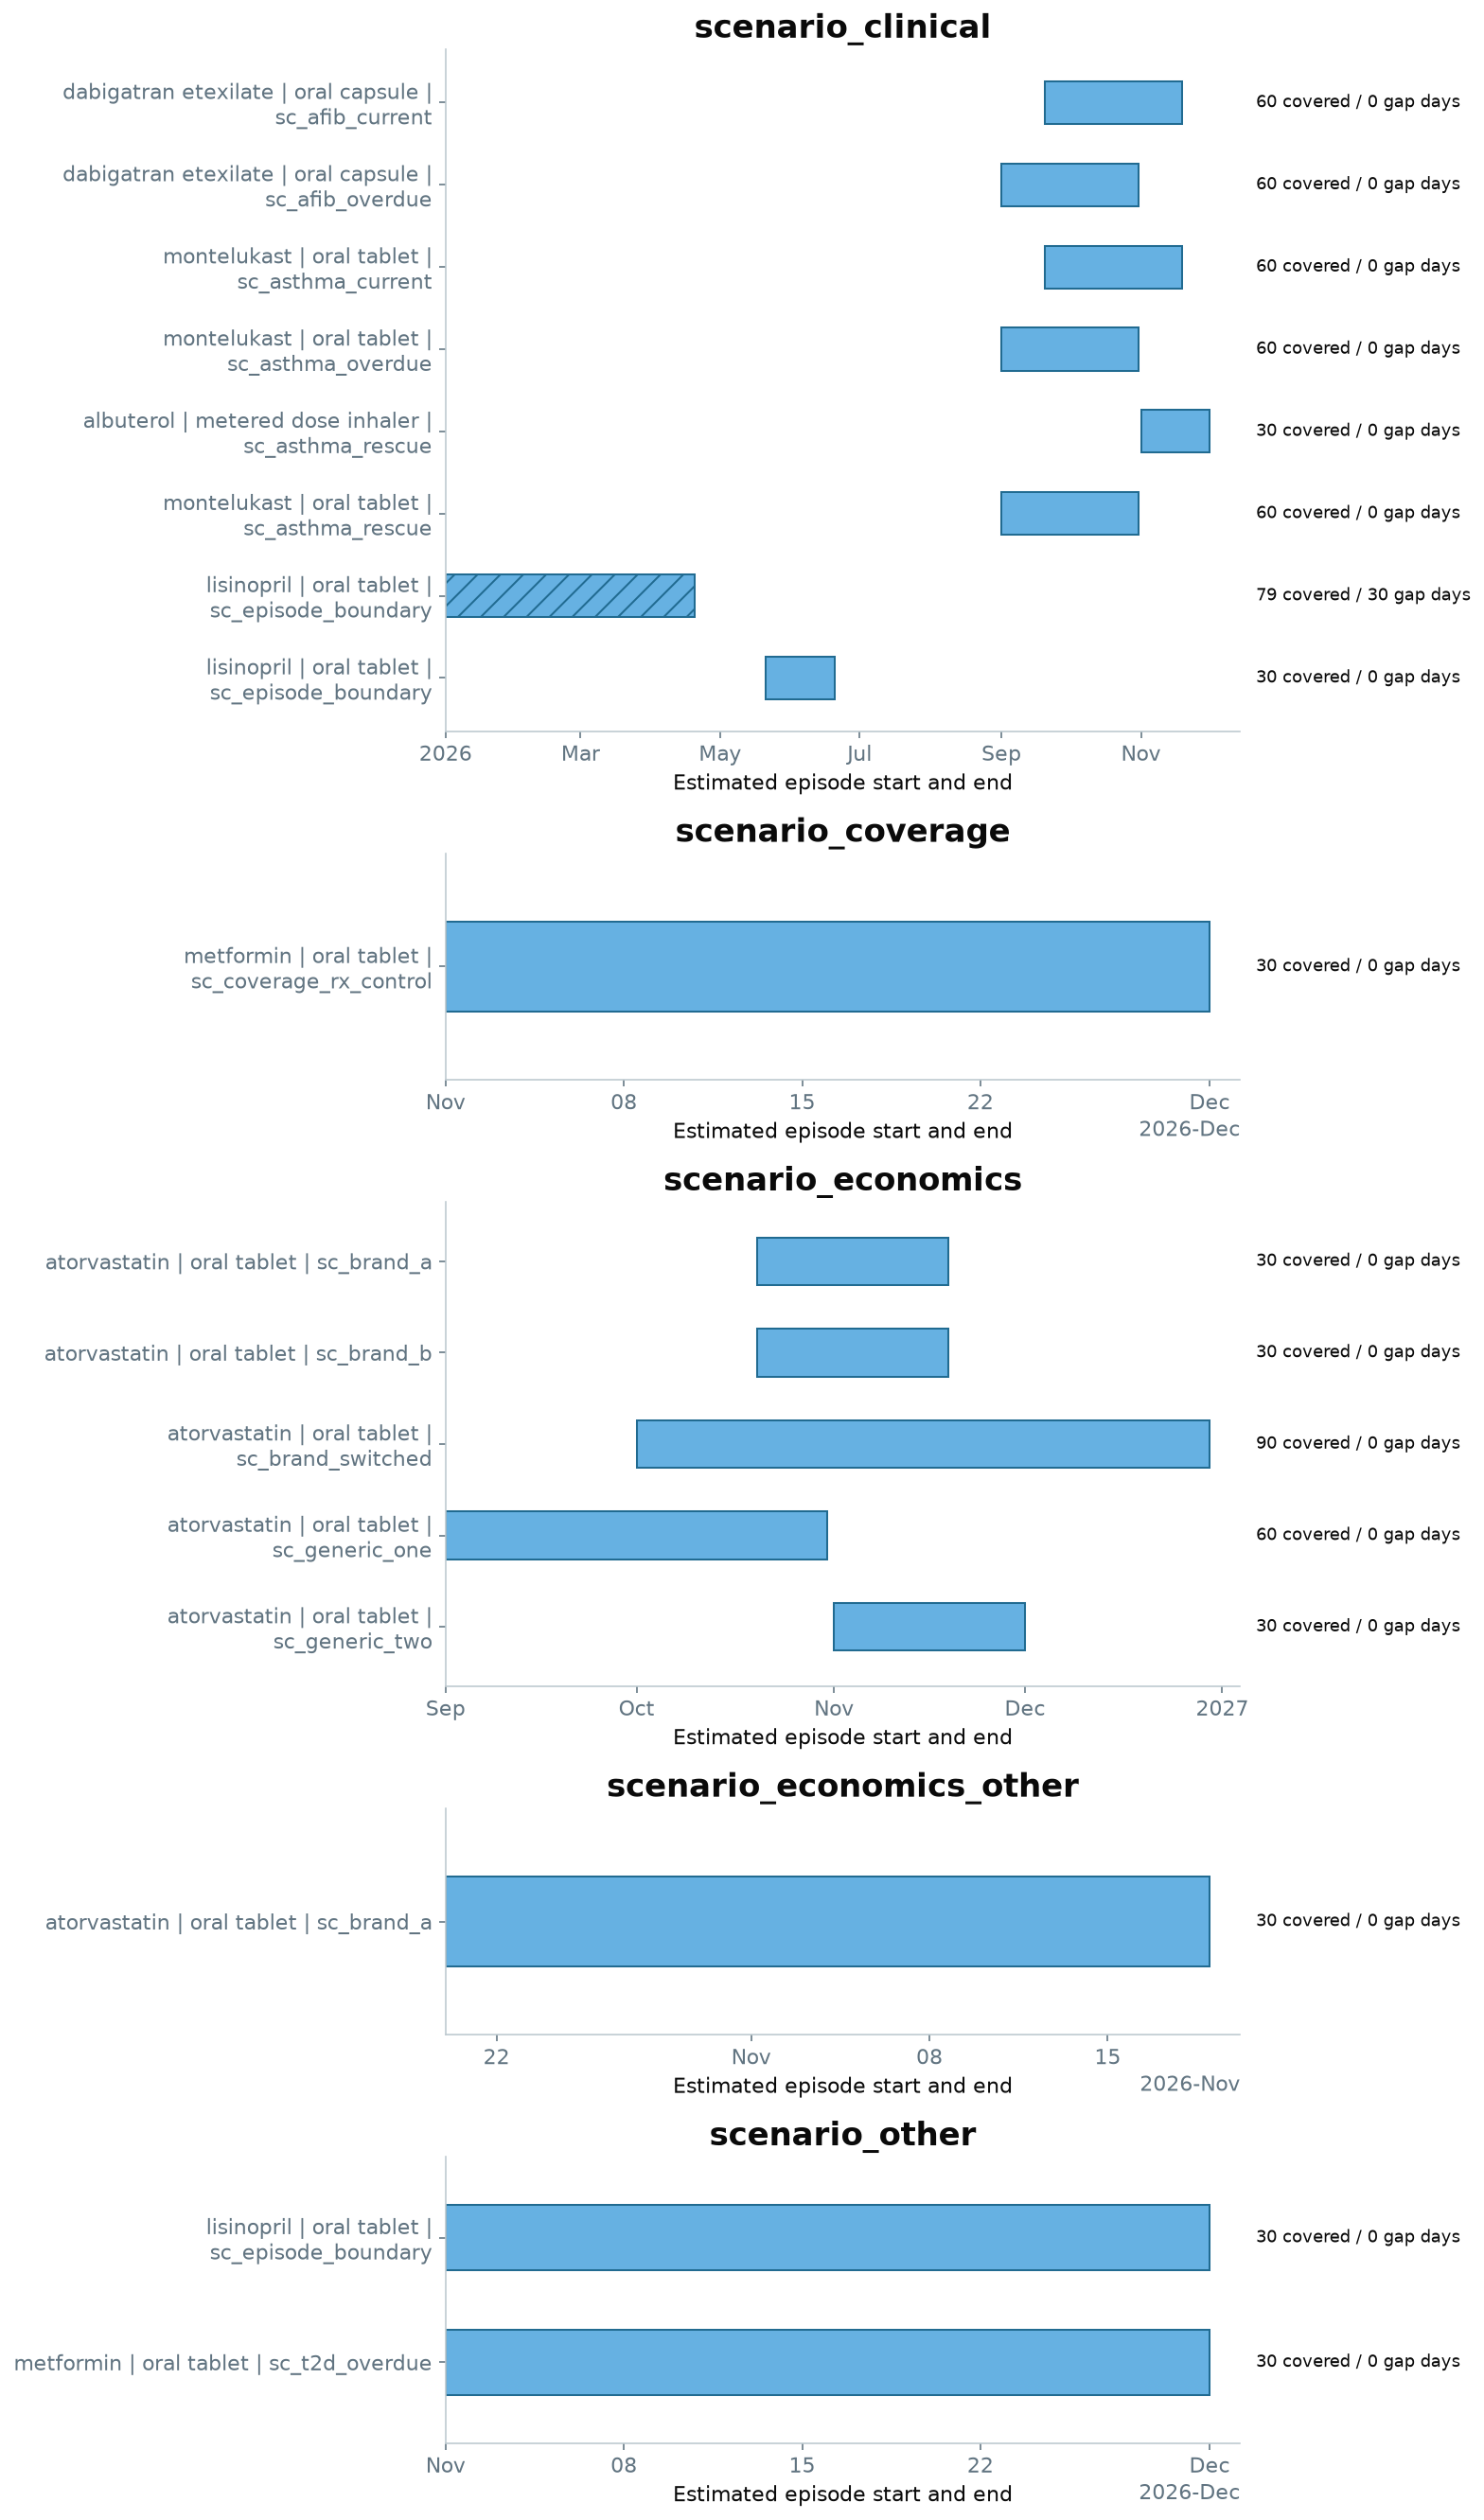

In [19]:
df = as_pandas(episodes_result)
if not episodes_enabled():
    enterprise_required('Drug Episodes')
elif df.empty:
    no_rows('Usable dispensing intervals and ingredient/form mappings are needed to construct an episode.')
else:
    df['start_date'] = pd.to_datetime(df.start_date)
    df['end_date'] = pd.to_datetime(df.end_date)
    sources = sorted(df.data_source.unique())
    panel_heights = [max(2.2, len(df[df.data_source.eq(s)]) * .64 + 1.5) for s in sources]
    fig, axes = plt.subplots(len(sources), 1, figsize=(11, sum(panel_heights)),
                             gridspec_kw={'height_ratios': panel_heights}, squeeze=False)
    for ax, source in zip(axes[:, 0], sources):
        part = df.loc[df.data_source.eq(source)].reset_index(drop=True)
        start = mdates.date2num(part.start_date)
        duration = (part.end_date - part.start_date).dt.days + 1
        for i, row in part.iterrows():
            ax.barh(i, duration.iloc[i], left=start[i], height=.52, color=SKY,
                    edgecolor=BLUE, hatch='//' if row.uncovered_days > 0 else None)
            ax.text(1.02, i, f'{int(row.covered_days)} covered / {int(row.uncovered_days)} gap days',
                    transform=ax.get_yaxis_transform(), va='center', fontsize=9, clip_on=False)
        ax.set(yticks=np.arange(len(part)),
               yticklabels=[wrap(f'{r.drug_name} | {r.dose_form_name} | {r.person_id}', 42) for r in part.itertuples()],
               title=wrap(source, 80), xlabel='Estimated episode start and end')
        locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.margins(x=.04)
        ax.set_ylim(-.65, len(part) - .35)
        ax.invert_yaxis()
    finish(fig, 'Bars show sampled episode spans, which can contain uncovered days. Hatching marks episodes with a gap; it does not identify the exact gap dates. Separate panels preserve each source’s time scale.')


**A span can contain uncovered days.** A January 1 fill with 30 days supply
ends January 30. A January 31 fill has no uncovered day; a February 1 fill has
one. Both remain in one episode under the default. The chart hatches spans
with uncovered days, while the table retains covered and uncovered totals.
This estimates treatment from dispensing history, not ingestion or confirmed
discontinuation.

**Constructed result.** The lisinopril oral-tablet course for
`sc_episode_boundary` in `scenario_clinical` spans January 1–April 19, with **79 covered days** and
**30 uncovered days**. Its May 21 fill starts another episode after 31
uncovered days.


In [20]:
SELECT *
FROM drugs.episode_mapping_quality
ORDER BY data_source;


data_source,medication_claim_count,usable_supply_claim_count,episode_mapped_claim_count,usable_claims_without_episode_mapping,usable_claims_without_ingredient,usable_claims_without_dose_form,unusable_supply_claim_count
medicare cclf,291,0,0,0,0,0,291
scenario_clinical,47,40,40,0,0,0,7
scenario_coverage,1,1,1,0,0,0,0
scenario_economics,7,7,7,0,0,0,0
scenario_economics_other,1,1,1,0,0,0,0
scenario_other,2,2,2,0,0,0,0


## Use the evidence behind each result

For medical economics, keep historical paid spending separate from prospective
switching savings. Review the clinical product, formulary context and pricing
evidence before treating a candidate as achievable savings.

For patient support, start with condition counts, then inspect people, fills,
uncertainty and freshness. Annual drug gaps and supply-based refills answer
different questions. Neither absence from a worklist nor a related claim proves
appropriate or complete treatment.

The episode method is informed by [OHDSI drug eras](https://ohdsi.github.io/CommonDataModel/cdm54.html#drug_era)
and [AdhereR](https://doi.org/10.1371/journal.pone.0174426). The class mappings
are Tuva analytic policy, not a complete prescribing protocol.
See [package configuration](https://github.com/tuva-health/drugs#configuration-and-data-freshness)
and [CodeRx Drug Database](https://thetuvaproject.com/coderx) for setup.
